# Introduction to Probability (Exercises and Solutions)



## **Problem & Solution**

  ### Problem 1
  You will be working on this [earthquake dataset](https://corgis-edu.github.io/corgis/csv/earthquakes/). From this dataset, you should plot some data and derive some statistics.

  1. Plot the histogram of the earthquake's magnitudes.
  1. What kind of distribution resembles?
  1. According to your observation, estimate the parameter(s).
  1. Assuming it's a Gaussian distribution,
    - estimate μ and σ (and plot the Gaussian on top of the histogram - don't forget the `density=True`).
  1. Plot the histogram of the hour of the day the earthquakes occurred (don't forget to set the number of [bins](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.hist.html) to a suitable number).
  1. What kind of distribution resembles?
  1. Now, if you got it correct, it is a distrubution that does not have _real_ paramaters, but a range. Estimate the range and, as such, and calculate the corresponding distrubution density function.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
!wget https://corgis-edu.github.io/corgis/datasets/csv/earthquakes/earthquakes.csv

--2023-10-31 12:03:03--  https://corgis-edu.github.io/corgis/datasets/csv/earthquakes/earthquakes.csv
Resolving corgis-edu.github.io (corgis-edu.github.io)... 185.199.108.153, 185.199.109.153, 185.199.110.153, ...
Connecting to corgis-edu.github.io (corgis-edu.github.io)|185.199.108.153|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1552196 (1.5M) [text/csv]
Saving to: ‘earthquakes.csv’

earthquakes.csv     100%[===================>]   1.48M  --.-KB/s    in 0.01s   

2023-10-31 12:03:03 (114 MB/s) - ‘earthquakes.csv’ saved [1552196/1552196]



In [ ]:
df = pd.read_csv('earthquakes.csv')

In [ ]:
df.shape

(8394, 18)

In [ ]:
df.head()

,id,impact.gap,impact.magnitude,impact.significance,location.depth,location.distance,location.full,location.latitude,location.longitude,location.name,time.day,time.epoch,time.full,time.hour,time.minute,time.month,time.second,time.year
0,nc72666881,122.00,1.43,31,15.12,0.10340,"13km E of Livermore, California",37.672333,-121.619000,California,27,1469593183550,2016-07-27 00:19:43,0,19,7,43,2016
1,us20006i0y,30.00,4.90,371,97.07,1.43900,"58km WNW of Pakokku, Burma",21.514600,94.572100,Burma,27,1469593228220,2016-07-27 00:20:28,0,20,7,28,2016
2,nc72666891,249.00,0.06,0,4.39,0.02743,"12km SE of Mammoth Lakes, California",37.576500,-118.859167,California,27,1469593897150,2016-07-27 00:31:37,0,31,7,37,2016
3,nc72666896,122.00,0.40,2,1.09,0.02699,"6km SSW of Mammoth Lakes, California",37.595833,-118.994833,California,27,1469594144150,2016-07-27 00:35:44,0,35,7,44,2016
4,nn00553447,113.61,0.30,1,7.60,0.06300,"16km SSE of Mogul, Nevada",39.377500,-119.845000,Nevada,27,1469594519667,2016-07-27 00:41:59,0,41,7,59,2016


#### **1. Plot the histogram of the earthquake's magnitudes.**

8 9 8
[3046. 3430. 1040.  219.  483.  156.   16.    4.] [0.01    0.97125 1.9325  2.89375 3.855   4.81625 5.7775  6.73875] <BarContainer object of 8 artists>


array([0.36287825, 0.40862521, 0.12389802, 0.02609006, 0.0575411 ,
       0.0185847 , 0.00190612, 0.00047653])

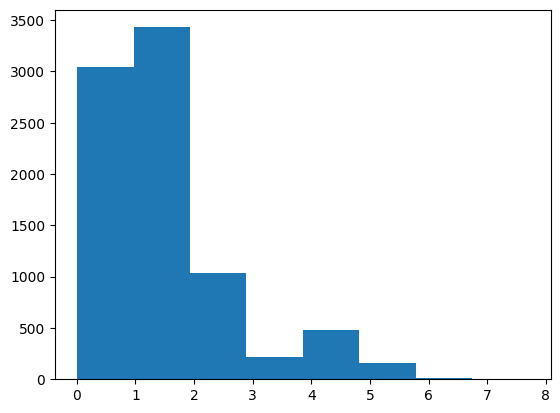

In [ ]:
freq, re, _ = plt.hist(df['impact.magnitude'], bins=8)
print (len(freq), len(re), len(_)) #8, 9, 8
#print (freq, re[:-1], _)

prob = freq/freq.sum()
prob

#### **2. What kind of distribution resembles?**

It seems like a ``Poisson distribution``. Let's estimate the parameter $\lambda$ of the Poisson distribution.

#### **3. According to your observation, estimate the parameter(s).**

In [ ]:
#expectation of the distribution, lambda = sum over probabilities * data

poisson_lambda =  np.sum(prob*re[:-1])
print('Poisson Distribution λ={:.2f}'.format(poisson_lambda))

Poisson Distribution λ=1.04


_Plotting the Poisson distribution for the estimated lambda_

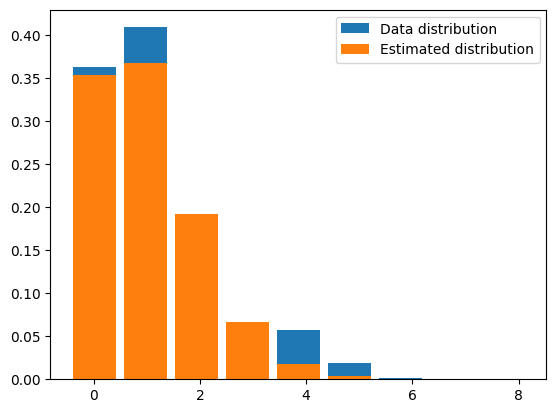

In [ ]:
poisson = lambda x, l : l**x*np.exp(-l)/np.asarray([np.math.factorial(int(k)) for k in x])

ax = plt.gca() #get the current axis
ax.bar(re[:-1], prob, label='Data distribution')
ax.bar(re, poisson(np.linspace(0, 8, re.shape[0]), poisson_lambda), label='Estimated distribution')
ax.legend()

#### **4. Assuming it's a Gaussian distribution**
  - Estimate $\mu$ and $\sigma$ (and plot the Gaussian on top of the histogram
  - Don't forget the `density=True`).

In [ ]:
m = df['impact.magnitude'].mean()
s = df['impact.magnitude'].std()

print('Gaussian Distribution, mean (μ)={:.2f}, standard deviation (σ)={:.2f}'.format(m,s))

Gaussian Distribution, mean (μ)=1.51, standard deviation (σ)=1.15


_Plotting the Gaussian on top of the histogram_
 - Don't forget the `density=True`

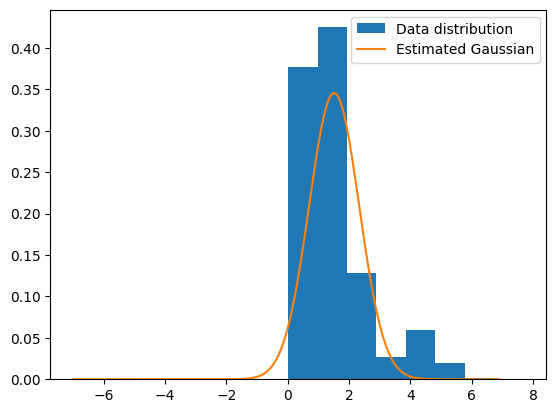

In [ ]:
gaussian = lambda x, mu, sigma: 1./(np.sqrt(2.*np.pi)*sigma) * np.exp( -(x-mu)**2/sigma**2)

ax = plt.gca() #get the current axis
x = np.arange(-7, 7,0.1)
#print (len(x), x)

plt.hist(df['impact.magnitude'], density=True, bins=8, label="Data distribution")
plt.plot(x, gaussian(x, m, s), label="Estimated Gaussian") #plot Gaussian
plt.legend()

#### **5.Plot the histogram of the hour of the day the earthquakes occurred**
  - Don't forget to set the number of bins to a suitable number

<Axes: >

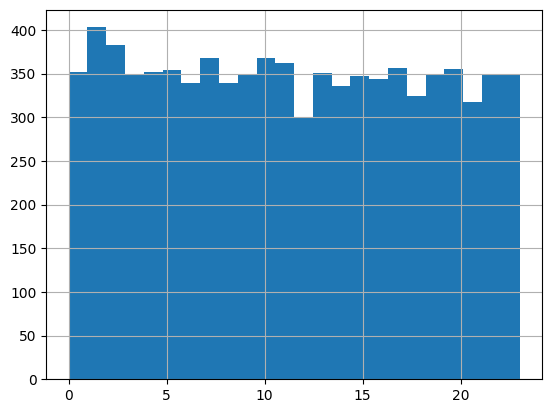

In [ ]:
ax = plt.gca()
df['time.hour'].hist(bins=24) #24 because we have 24 hours in a day

#### **6. What kind of distribution resembles?**

  It seems like an ``uniform distribution`` of a continuous variable, which has a range (0 to 28), probably.

#### **7. If you got it correct, it is a distrubution that does not have real paramaters, but a range.**
  - Estimate the range and,
  - Calculate the corresponding distrubution density function

In [ ]:
df['time.hour'].describe()

count    8394.000000
mean       11.323922
std         6.967305
min         0.000000
25%         5.000000
50%        11.000000
75%        17.000000
max        23.000000
Name: time.hour, dtype: float64

- Minimum (a) = 0.0
- Maximum (b) = 23

- Let's calculate the uniform distribution for the range (a, b)

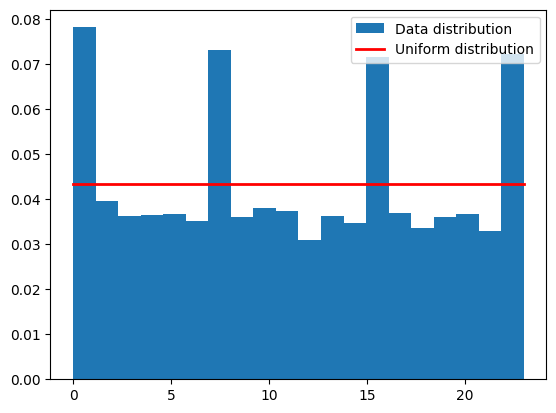

In [ ]:
a = df['time.hour'].min()
b = df['time.hour'].max()
range = b - a
uniform_density = lambda a, b: 1.0/(b - a)
p_x = uniform_density(a, b)

ax = plt.gca()
count, bins, ignored = plt.hist(df['time.hour'], bins='auto', density=True, label='Data distribution')
plt.plot(bins, [p_x for _ in bins], linewidth=2, color='r', label='Uniform distribution')
plt.legend()

### Problem 2

1. A certain disease affects about 10 out of 10,000 people. There is a test to check whether the person has the disease. The test is quite accurate. In particular, we know <br/>
(a) The probability that the test result is positive given the person is healthy is 5 percent. <br/>
(b) the probability that the test result is negative given that the person has the disease is only 3 percent.

A random person gets tested for the disease and the result comes back positive. What is the probability that the person has the disease?

In [ ]:
"""
  # H = A healthy person
  # D = The person has the disease
  # P = Positive test
  # N = Negative test
"""

# A certain disease affects about 10 out of 10,000 people.
prob_D = 10.0/10000
prob_H = 1.0 - prob_D

# Probability that the test result is positive given the person is healthy is 5 percent.

prob_P_H = 0.05
prob_P_D = 1.0 - prob_P_H # Prob (A) + Prob (B) = 1

# Probability that the test result is negative given that the person has the disease is only 3 percent
prob_N_D = 0.03
prob_N_H = 1.0 - prob_N_D

# A random person gets tested for the disease and the result comes back positive.
# What is the probability that the person has the disease?
# prob_D_P = ?

# Bayes' rule
prob_D_P = (prob_P_D * prob_D) / (prob_P_D * prob_D + prob_P_H * prob_H)

print('P(Disease | Test = +) = {}'.format(prob_D_P))

P(D | Test =+) = 0.018664047151277015


2. Assume the probability of having tuberculosis (TB) is 0.0005, and a test for TB is 99% accurate. <br/>
(a) What is the probability one has TB if one tests positive for the disease? <br/>
(b) What is the probability one hasn't TB if one tests positive for the disease?

In [ ]:
'''
  TB = Tuberculosis
  NT = Not Tuberculosis
'''

# the probability of having tuberculosis (TB) is 0.0005
prob_TB = 0.0005
prob_NTB = 1.0 - prob_TB

# a test for TB is 99% accurate
prob_P_TB = 0.99 #probability of getting positive test if someone has TB
prob_P_NTB = 1.0 - 0.99

# the probability that one person has TB if the test positive for the disease
# prob_TB_P = ?

prob_TB_P = (prob_P_TB * prob_TB)/(prob_P_TB * prob_TB + prob_P_NTB * prob_NTB)
print('P(TB | Test = +) = {:.3f}'.format(prob_TB_P))

# the probability that one person hasn't TB if the test positive for the disease?
# prob_NTB_P = ?
prob_NTB_P = (prob_P_NTB * prob_NTB)/(prob_P_NTB * prob_NTB + prob_P_TB * prob_TB)
print('P(NTB | Test = +) = {:.3f}'.format(prob_NTB_P))

P(TB | Test = +) = 0.047
P(NTB | Test = +) = 0.953
